# Class project => learning how to manipulate the netCDF files

### extracting the necessary variables, plotting them, and writing them to a file

In [7]:
# import standard libraries
from IPython.display import IFrame
%matplotlib inline
import matplotlib.pyplot as plt
import getpass
import xarray as xr
import panel.widgets as pnw
import panel as pn
import pandas as pd
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import copernicusmarine
import datetime
import numpy
import sys
import os
from pylab import *
import csv

# setting-up the paths
root_dir = os.getcwd()
print(root_dir)

# insert path where the local library is located
sys.path.insert(0,root_dir)

# import local library
import wavetools.loaders.read_global_wave_ENPC as rdwv

# set the local data directory
datadir = os.path.join(root_dir,'data')
print(datadir)

# set out_dir to save the plots
outdir = os.path.join(root_dir,'img/04_01')

# To avoid warning messages
import warnings
warnings.filterwarnings('ignore')


/home/marissa.yates@enpc.fr/Travail/Copernicus
/home/marissa.yates@enpc.fr/Travail/Copernicus/data


In [9]:
# input the nc file name to examine
fname = 'cmems_mod_glo_wav_my_0.2deg_PT3H-i_1729603460761.nc'
ncfile = datadir + '/' + fname

DS = xr.open_dataset(ncfile)
DS

<xarray.Dataset> Size: 2MB
Dimensions:    (time: 88616, latitude: 1, longitude: 1)
Coordinates:
  * time       (time) datetime64[ns] 709kB 1993-01-01 ... 2023-04-30T21:00:00
  * latitude   (latitude) float32 4B 49.8
  * longitude  (longitude) float32 4B -0.8
Data variables:
    VHM0       (time, latitude, longitude) float32 354kB ...
    VMDR       (time, latitude, longitude) float32 354kB ...
    VTM02      (time, latitude, longitude) float32 354kB ...
Attributes:
    Conventions:       CF-1.11
    title:             Mean fields from global wave model MFWAM of Meteo-Fran...
    institution:       METEO-FRANCE
    producer:          CMEMS - Global Monitoring and Forecasting Centre
    credit:            E.U. Copernicus Marine Service Information (CMEMS)
    contact:           servicedesk.cmems@mercator-ocean.eu
    references:        http://marine.copernicus.eu
    subset:source:     ARCO data downloaded from the Marine Data Store using ...
    subset:productId:  GLOBAL_MULTIYEAR_WAV_001_032
    subset:datasetId:  cmems_mod_glo_wav_my_0.2deg_PT3H-i_202311
    subset:date:       2024-10-22T13:24:20.761Z

---
## Data Exploration

The Copernicus Marine Service provides several mechanisms for users to access and obtain its products: _[Copernicus Marine Client API - Open a dataset or read a dataframe remotely](https://help.marine.copernicus.eu/en/articles/8287609-copernicus-marine-client-api-open-a-dataset-or-read-a-dataframe-remotely#h_71eee6dbce)_ \
⚠️ For all of them, your Copernicus Marine credentials are **required**.

For our use case, we will access the data with the [copernicusmarine](https://help.marine.copernicus.eu/en/articles/7949409-copernicus-marine-client-introduction) toolbox.

To start, let's first open the **entire dataset**, that we'll store in the variable <code>DS</code>. \
We will see later how to select parameters (cf. [Plot Data](#Plot-Data)).

In [10]:
# General information about the data
DS.info

<bound method Dataset.info of <xarray.Dataset> Size: 2MB
Dimensions:    (time: 88616, latitude: 1, longitude: 1)
Coordinates:
  * time       (time) datetime64[ns] 709kB 1993-01-01 ... 2023-04-30T21:00:00
  * latitude   (latitude) float32 4B 49.8
  * longitude  (longitude) float32 4B -0.8
Data variables:
    VHM0       (time, latitude, longitude) float32 354kB ...
    VMDR       (time, latitude, longitude) float32 354kB ...
    VTM02      (time, latitude, longitude) float32 354kB ...
Attributes:
    Conventions:       CF-1.11
    title:             Mean fields from global wave model MFWAM of Meteo-Fran...
    institution:       METEO-FRANCE
    producer:          CMEMS - Global Monitoring and Forecasting Centre
    credit:            E.U. Copernicus Marine Service Information (CMEMS)
    contact:           servicedesk.cmems@mercator-ocean.eu
    references:        http://marine.copernicus.eu
    subset:source:     ARCO data downloaded from the Marine Data Store using ...
    subset:prod

In [11]:
# Get the full list of variables available in the dataset
DS.data_vars

Data variables:
    VHM0     (time, latitude, longitude) float32 354kB ...
    VMDR     (time, latitude, longitude) float32 354kB ...
    VTM02    (time, latitude, longitude) float32 354kB ...

In [12]:
# Get the list of dimensions
DS.coords

Coordinates:
  * time       (time) datetime64[ns] 709kB 1993-01-01 ... 2023-04-30T21:00:00
  * latitude   (latitude) float32 4B 49.8
  * longitude  (longitude) float32 4B -0.8

In [13]:
# Get info on one specific variable (here Hm0)
DS.VHM0

<xarray.DataArray 'VHM0' (time: 88616, latitude: 1, longitude: 1)> Size: 354kB
[88616 values with dtype=float32]
Coordinates:
  * time       (time) datetime64[ns] 709kB 1993-01-01 ... 2023-04-30T21:00:00
  * latitude   (latitude) float32 4B 49.8
  * longitude  (longitude) float32 4B -0.8
Attributes:
    units:          m
    standard_name:  sea_surface_wave_significant_height
    long_name:      Spectral significant wave height (Hm0)

In [14]:
# Get info on specific dimensions 
DS.time

<xarray.DataArray 'time' (time: 88616)> Size: 709kB
array(['1993-01-01T00:00:00.000000000', '1993-01-01T03:00:00.000000000',
       '1993-01-01T06:00:00.000000000', ..., '2023-04-30T15:00:00.000000000',
       '2023-04-30T18:00:00.000000000', '2023-04-30T21:00:00.000000000'],
      shape=(88616,), dtype='datetime64[ns]')
Coordinates:
  * time     (time) datetime64[ns] 709kB 1993-01-01 ... 2023-04-30T21:00:00
Attributes:
    standard_name:  time
    long_name:      Time
    axis:           T

In [15]:
# Define the target period of interest (here, the entire timeseries)
target_t_period=slice("1993-01-01","2023-04-30")
#target_t_period=slice("2023-01-01","2023-04-30")


Text(0.5, 1.0, 'Mean wave direction from (Mdir) monthly evolution')

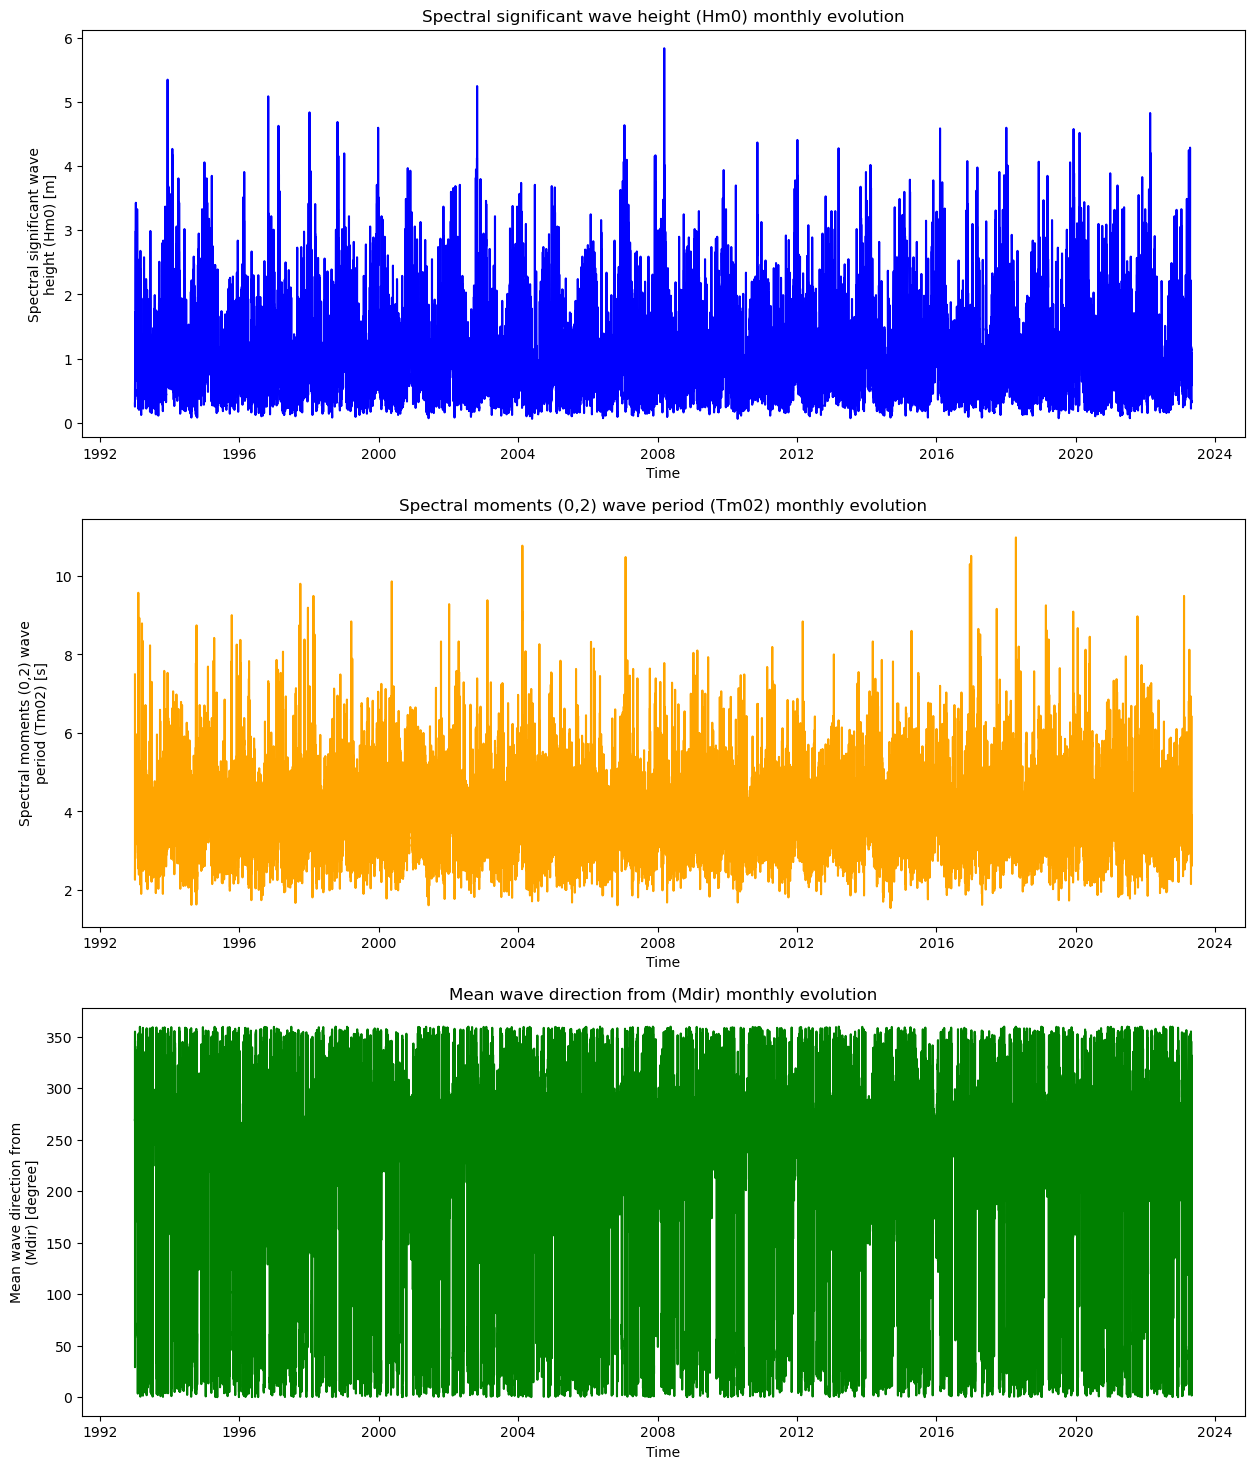

In [9]:
# Plotting the timeseries
HM0 = DS.VHM0.sel(time = target_t_period)
TM02 = DS.VTM02.sel(time = target_t_period)
DIRM = DS.VMDR.sel(time = target_t_period)
time = DS.time.sel(time = target_t_period)
# AT HM0 FP DIR
plt.figure(figsize=(15,18))

plt.subplot(3, 1, 1)
HM0.plot(color = 'blue')
plt.title(f"{HM0.long_name} monthly evolution")

plt.subplot(3, 1, 2)
TM02.plot(color = 'orange')
plt.title(f"{TM02.long_name} monthly evolution")

plt.subplot(3, 1, 3)
DIRM.plot(color = 'green')
plt.title(f"{DIRM.long_name} monthly evolution")

In [15]:
# Save the data 
subset = DS[['time','VHM0','VTM02','VMDR']].sel(time = target_t_period)
subset

a = np.squeeze(xr.DataArray(subset.variables['VHM0']))
b = np.squeeze(xr.DataArray(subset.variables['VTM02']))
c = np.squeeze(xr.DataArray(subset.variables['VMDR']))

# calculate time in seconds for the 3hr window
#at = np.arange(len(a))*3*60*60
#headertxt = 'Variables \n AT HM0 FP DIR'

# output the time step 
tt = np.squeeze(xr.DataArray(subset.variables['time']))
headertxt = 'Variables \n DATE HM0 FP DIR'

# make sure not to overwrite an existing file, and assign the same number to 
# the associated time file
def nextnonexistent(f):
    fnew = f
    tnew='time.txt'
    root, ext = os.path.splitext(f)
    i = 0
    while os.path.exists(fnew):
        i += 1
        fnew = '%s%i%s' % (root, i, ext)
        tnew = '%s%i%s' % ('time', i, ext)   
    return fnew,tnew

fout = 'output.txt'
fout,tout = nextnonexistent(fout)
with open(fout, 'a') as f:
    #f.write('# number of time steps \n'+str(len(a))+'\n')
    np.savetxt(f,np.vstack((a,b,c)).T,delimiter='   ', fmt='%s', newline='\n', header=headertxt)

np.savetxt(tout,np.vstack((time)),delimiter='   ', fmt='%s')